In [23]:
import pandas as pd
import numpy as np

# ============================================================================
# 1. LOAD CLEANED DATA & PRE-PROCESS NEW TABLES
# ============================================================================
base_path = '..\\ACL_9th-F1\\F1_clean\\'

results = pd.read_csv('..\\ACL_9th-F1\\F1_clean\\results_clean_with_rank.csv')
races = pd.read_csv(base_path + 'races_clean.csv')
driver_standings = pd.read_csv(base_path + 'driver_standings_clean.csv')
qualifying = pd.read_csv('..\\ACL_9th-F1\\F1\\' + 'qualifying.csv')
drivers = pd.read_csv(base_path + 'drivers_clean.csv')
circuits = pd.read_csv(base_path + 'circuits_clean.csv')
constructors = pd.read_csv(base_path + 'constructors_clean.csv')
results['podium'] = (results['positionOrder'] <= 3).astype(int)
# Load the new tables
lap_times = pd.read_csv('..\\ACL_9th-F1\\F1\\lap_times.csv')
pit_stops = pd.read_csv('..\\ACL_9th-F1\\F1\\pit_stops.csv')
constructor_standings = pd.read_csv('..\\ACL_9th-F1\\F1\\constructor_standings.csv')

# Pre-process 'rank' (fastest lap rank) to numeric, converting '\N' to NaN
if 'rank' in results.columns:
    results['rank'] = pd.to_numeric(results['rank'].replace(r'\N', np.nan), errors='coerce')

# Aggregate average lap position per driver per race
race_lap_avg = lap_times.groupby(['raceId', 'driverId'])['position'].mean().reset_index(name='race_avg_lap_pos')

# Aggregate average pit stop duration per driver per race
pit_avg = pit_stops.groupby(['raceId', 'driverId'])['milliseconds'].mean().reset_index(name='race_avg_pit_ms')

# =============================================================================
# 2. DRIVER FORM FEATURES (Carries over between seasons)
# =============================================================================
# Merge results with races and new aggregates to sort chronologically
driver_form = results[['raceId', 'driverId', 'positionOrder', 'podium', 'rank']].copy()
driver_form = driver_form.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')
driver_form = driver_form.merge(race_lap_avg, on=['raceId', 'driverId'], how='left')
driver_form = driver_form.merge(pit_avg, on=['raceId', 'driverId'], how='left')

# Sort chronologically by driver
driver_form = driver_form.sort_values(by=['driverId', 'race_year', 'race_round'])

# --- RECENT FORM (Shifted to exclude current race) ---
driver_form['driver_prev_position'] = driver_form.groupby('driverId')['positionOrder'].shift(1)
driver_form['driver_prev_podium'] = driver_form.groupby('driverId')['podium'].shift(1).fillna(0)

shifted_group = driver_form.groupby('driverId').shift(1)

# Rolling 5-Race Averages
driver_form['driver_avg_pos_last_5'] = shifted_group['positionOrder'].rolling(window=5, min_periods=1).mean()
driver_form['driver_avg_lap_pos_last_5'] = shifted_group['race_avg_lap_pos'].rolling(window=5, min_periods=1).mean()
driver_form['driver_avg_pit_ms_last_5'] = shifted_group['race_avg_pit_ms'].rolling(window=5, min_periods=1).mean()
driver_form['driver_avg_speed_rank_last_5'] = shifted_group['rank'].rolling(window=5, min_periods=1).mean()

# --- CAREER TOTALS (Expanding to include all past races) ---
driver_form['driver_career_avg_pos'] = shifted_group['positionOrder'].expanding().mean()
driver_form['driver_career_podiums'] = shifted_group['podium'].expanding().sum().fillna(0)

# Isolate columns for final merge
driver_features_to_keep = [
    'raceId', 'driverId', 'driver_prev_position', 'driver_prev_podium', 
    'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_pit_ms_last_5', 
    'driver_avg_speed_rank_last_5', 'driver_career_avg_pos', 'driver_career_podiums'
]
driver_form = driver_form[driver_features_to_keep]

# =============================================================================
# 3. DRIVER STANDINGS FEATURES (Resets to 0 every season)
# =============================================================================
ds = driver_standings.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')
ds = ds.sort_values(by=['driverId', 'race_year', 'race_round'])

ds['pre_race_points'] = ds.groupby(['driverId', 'race_year'])['driver_points_cumm'].shift(1).fillna(0)
ds['pre_race_wins'] = ds.groupby(['driverId', 'race_year'])['driver_wins_cumm'].shift(1).fillna(0)
ds['won_previous_race'] = ds.groupby(['driverId', 'race_year'])['pre_race_wins'].diff().fillna(0)

ds = ds[['raceId', 'driverId', 'pre_race_points', 'pre_race_wins', 'won_previous_race']]

# =============================================================================
# 3.5 CONSTRUCTOR FORM & STANDINGS (NEW)
# =============================================================================
# --- CONSTRUCTOR FORM ---
constructor_form = results[['raceId', 'constructorId', 'positionOrder', 'podium']].copy()
constructor_form = constructor_form.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')

# Best finish and total podiums for the team per race
constructor_form = constructor_form.groupby(['raceId', 'constructorId', 'race_year', 'race_round']).agg({
    'positionOrder': 'min',
    'podium': 'sum'
}).reset_index()

constructor_form = constructor_form.sort_values(by=['constructorId', 'race_year', 'race_round'])
shifted_constructor = constructor_form.groupby('constructorId').shift(1)

constructor_form['constructor_prev_pos'] = shifted_constructor['positionOrder']
constructor_form['constructor_avg_pos_last_5'] = shifted_constructor['positionOrder'].rolling(window=5, min_periods=1).mean()
constructor_form['constructor_career_podiums'] = shifted_constructor['podium'].expanding().sum().fillna(0)

constructor_form = constructor_form[['raceId', 'constructorId', 'constructor_prev_pos', 'constructor_avg_pos_last_5', 'constructor_career_podiums']]

# --- CONSTRUCTOR STANDINGS ---
cs = constructor_standings.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')
cs = cs.sort_values(by=['constructorId', 'race_year', 'race_round'])

# Adjust column names 'constructor_points_cumm'/'constructor_wins_cumm' if they differ in your CSV
cs['pre_race_constructor_points'] = cs.groupby(['constructorId', 'race_year'])['points'].shift(1).fillna(0)
cs['pre_race_constructor_wins'] = cs.groupby(['constructorId', 'race_year'])['wins'].shift(1).fillna(0)

cs = cs[['raceId', 'constructorId', 'pre_race_constructor_points', 'pre_race_constructor_wins']]

# =============================================================================
# 4. BUILD THE BASE TRAINING TABLE (Strict Leakage Control)
# =============================================================================
final_df = results[['raceId', 'driverId', 'constructorId', 'grid', 'podium']].copy()

final_df = final_df.merge(races[['raceId', 'race_year', 'race_round', 'circuitId']], on='raceId', how='left')

final_df = final_df.merge(qualifying[['raceId', 'driverId', 'position']], on=['raceId', 'driverId'], how='left')
final_df.rename(columns={'position': 'quali_position'}, inplace=True)

final_df = final_df.merge(drivers[['driverId', 'drivers_nationality']], on='driverId', how='left')
final_df.rename(columns={'drivers_nationality': 'driver_nationality'}, inplace=True)

final_df = final_df.merge(circuits[['circuitId', 'country']], on='circuitId', how='left')
final_df.rename(columns={'country': 'circuit_country'}, inplace=True)

final_df = final_df.merge(constructors[['constructorId', 'name']], on='constructorId', how='left')
final_df.rename(columns={'name': 'constructor_name'}, inplace=True)

final_df = final_df.merge(driver_form, on=['raceId', 'driverId'], how='left')
final_df = final_df.merge(ds, on=['raceId', 'driverId'], how='left')

# Add Constructor details
final_df = final_df.merge(constructor_form, on=['raceId', 'constructorId'], how='left')
final_df = final_df.merge(cs, on=['raceId', 'constructorId'], how='left')

# =============================================================================
# 5. HOME RACE FEATURE ENGINEERING
# =============================================================================
# Dictionary mapping F1 nationalities to circuit countries
nationality_to_country = {
    'British': 'UK', 'German': 'Germany', 'Spanish': 'Spain', 'Finnish': 'Finland',
    'Japanese': 'Japan', 'French': 'France', 'Polish': 'Poland', 'Brazilian': 'Brazil',
    'Italian': 'Italy', 'Australian': 'Australia', 'Austrian': 'Austria', 'American': 'USA',
    'Dutch': 'Netherlands', 'Colombian': 'Colombia', 'Portuguese': 'Portugal', 
    'Canadian': 'Canada', 'Indian': 'India', 'Hungarian': 'Hungary', 'Irish': 'Ireland',
    'Danish': 'Denmark', 'Argentine': 'Argentina', 'Belgian': 'Belgium', 
    'South African': 'South Africa', 'Swiss': 'Switzerland', 'Swedish': 'Sweden',
    'Mexican': 'Mexico', 'Russian': 'Russia', 'Chinese': 'China', 
    'Monegasque': 'Monaco', 'New Zealander': 'New Zealand'
}

final_df['driver_home_country'] = final_df['driver_nationality'].map(nationality_to_country).fillna(final_df['driver_nationality'])
# final_df['circuit_country'] = final_df['circuit_country'].replace({'United States': 'USA'})
final_df['is_home_race'] = (final_df['driver_home_country'] == final_df['circuit_country']).astype(int)
final_df = final_df.drop(columns=['driver_home_country'])

# =============================================================================
# 6. FINAL CLEANUP & EXPORT
# =============================================================================
# 6A. Fill Qualifying Drift using Grid position (replacing pit lane '0' with '20')
temp_grid = final_df['grid'].replace(0, 20)
final_df['quali_position'] = final_df['quali_position'].fillna(temp_grid)

# 6B. Fill zero-baselines for debuts
final_df['pre_race_points'] = final_df['pre_race_points'].fillna(0)
final_df['pre_race_wins'] = final_df['pre_race_wins'].fillna(0)
final_df['won_previous_race'] = final_df['won_previous_race'].fillna(0)
final_df['driver_prev_podium'] = final_df['driver_prev_podium'].fillna(0)
final_df['pre_race_constructor_points'] = final_df['pre_race_constructor_points'].fillna(0)
final_df['pre_race_constructor_wins'] = final_df['pre_race_constructor_wins'].fillna(0)

# 6C. Fill rookie/debut Form with "back of pack" baseline (20)
final_df['driver_prev_position'] = final_df['driver_prev_position'].fillna(20)
final_df['driver_avg_pos_last_5'] = final_df['driver_avg_pos_last_5'].fillna(20)
final_df['driver_career_avg_pos'] = final_df['driver_career_avg_pos'].fillna(20)
final_df['constructor_prev_pos'] = final_df['constructor_prev_pos'].fillna(20)
final_df['constructor_avg_pos_last_5'] = final_df['constructor_avg_pos_last_5'].fillna(20)

# 6D. Fill missing lap/pit stop data (due to decades of missing coverage)
final_df['driver_avg_speed_rank_last_5'] = final_df['driver_avg_speed_rank_last_5'].fillna(20)
final_df['driver_avg_lap_pos_last_5'] = final_df['driver_avg_lap_pos_last_5'].fillna(20)
# Fill missing pit stop milliseconds with a heavy penalty (e.g. 40000ms / 40s)
final_df['driver_avg_pit_ms_last_5'] = final_df['driver_avg_pit_ms_last_5'].fillna(40000)

final_df.to_csv(base_path + 'FINAL_training_table.csv', index=False)

print(f"Final Training Table built successfully! Shape: {final_df.shape}")
print("Columns:", final_df.columns.tolist())

Final Training Table built successfully! Shape: (26668, 29)
Columns: ['raceId', 'driverId', 'constructorId', 'grid', 'podium', 'race_year', 'race_round', 'circuitId', 'quali_position', 'driver_nationality', 'circuit_country', 'constructor_name', 'driver_prev_position', 'driver_prev_podium', 'driver_avg_pos_last_5', 'driver_avg_lap_pos_last_5', 'driver_avg_pit_ms_last_5', 'driver_avg_speed_rank_last_5', 'driver_career_avg_pos', 'driver_career_podiums', 'pre_race_points', 'pre_race_wins', 'won_previous_race', 'constructor_prev_pos', 'constructor_avg_pos_last_5', 'constructor_career_podiums', 'pre_race_constructor_points', 'pre_race_constructor_wins', 'is_home_race']


In [26]:
final_df.isnull().sum()

raceId                          0
driverId                        0
constructorId                   0
grid                            0
podium                          0
race_year                       0
race_round                      0
circuitId                       0
quali_position                  0
driver_nationality              0
circuit_country                 0
constructor_name                0
driver_prev_position            0
driver_prev_podium              0
driver_avg_pos_last_5           0
driver_avg_lap_pos_last_5       0
driver_avg_pit_ms_last_5        0
driver_avg_speed_rank_last_5    0
driver_career_avg_pos           0
driver_career_podiums           0
pre_race_points                 0
pre_race_wins                   0
won_previous_race               0
constructor_prev_pos            0
constructor_avg_pos_last_5      0
constructor_career_podiums      0
pre_race_constructor_points     0
pre_race_constructor_wins       0
is_home_race                    0
dtype: int64

--- Correlation Matrix (X features vs Y target) ---
                              quali_position      grid    podium  \
quali_position                      1.000000  0.764230 -0.449732   
grid                                0.764230  1.000000 -0.364845   
podium                             -0.449732 -0.364845  1.000000   
driver_avg_pos_last_5               0.593524  0.318811 -0.351103   
pre_race_points                    -0.380266 -0.291035  0.317099   
pre_race_wins                      -0.352614 -0.284829  0.370284   
won_previous_race                  -0.251604 -0.206662  0.254660   
is_home_race                        0.068158  0.059211 -0.019443   
driver_prev_position                0.462078  0.244618 -0.273774   
driver_prev_podium                 -0.391406 -0.311441  0.350418   
driver_avg_lap_pos_last_5           0.362319  0.227163 -0.199390   
driver_avg_pit_ms_last_5           -0.041493 -0.026343  0.010715   
driver_avg_speed_rank_last_5        0.290316  0.182672 -0.162322

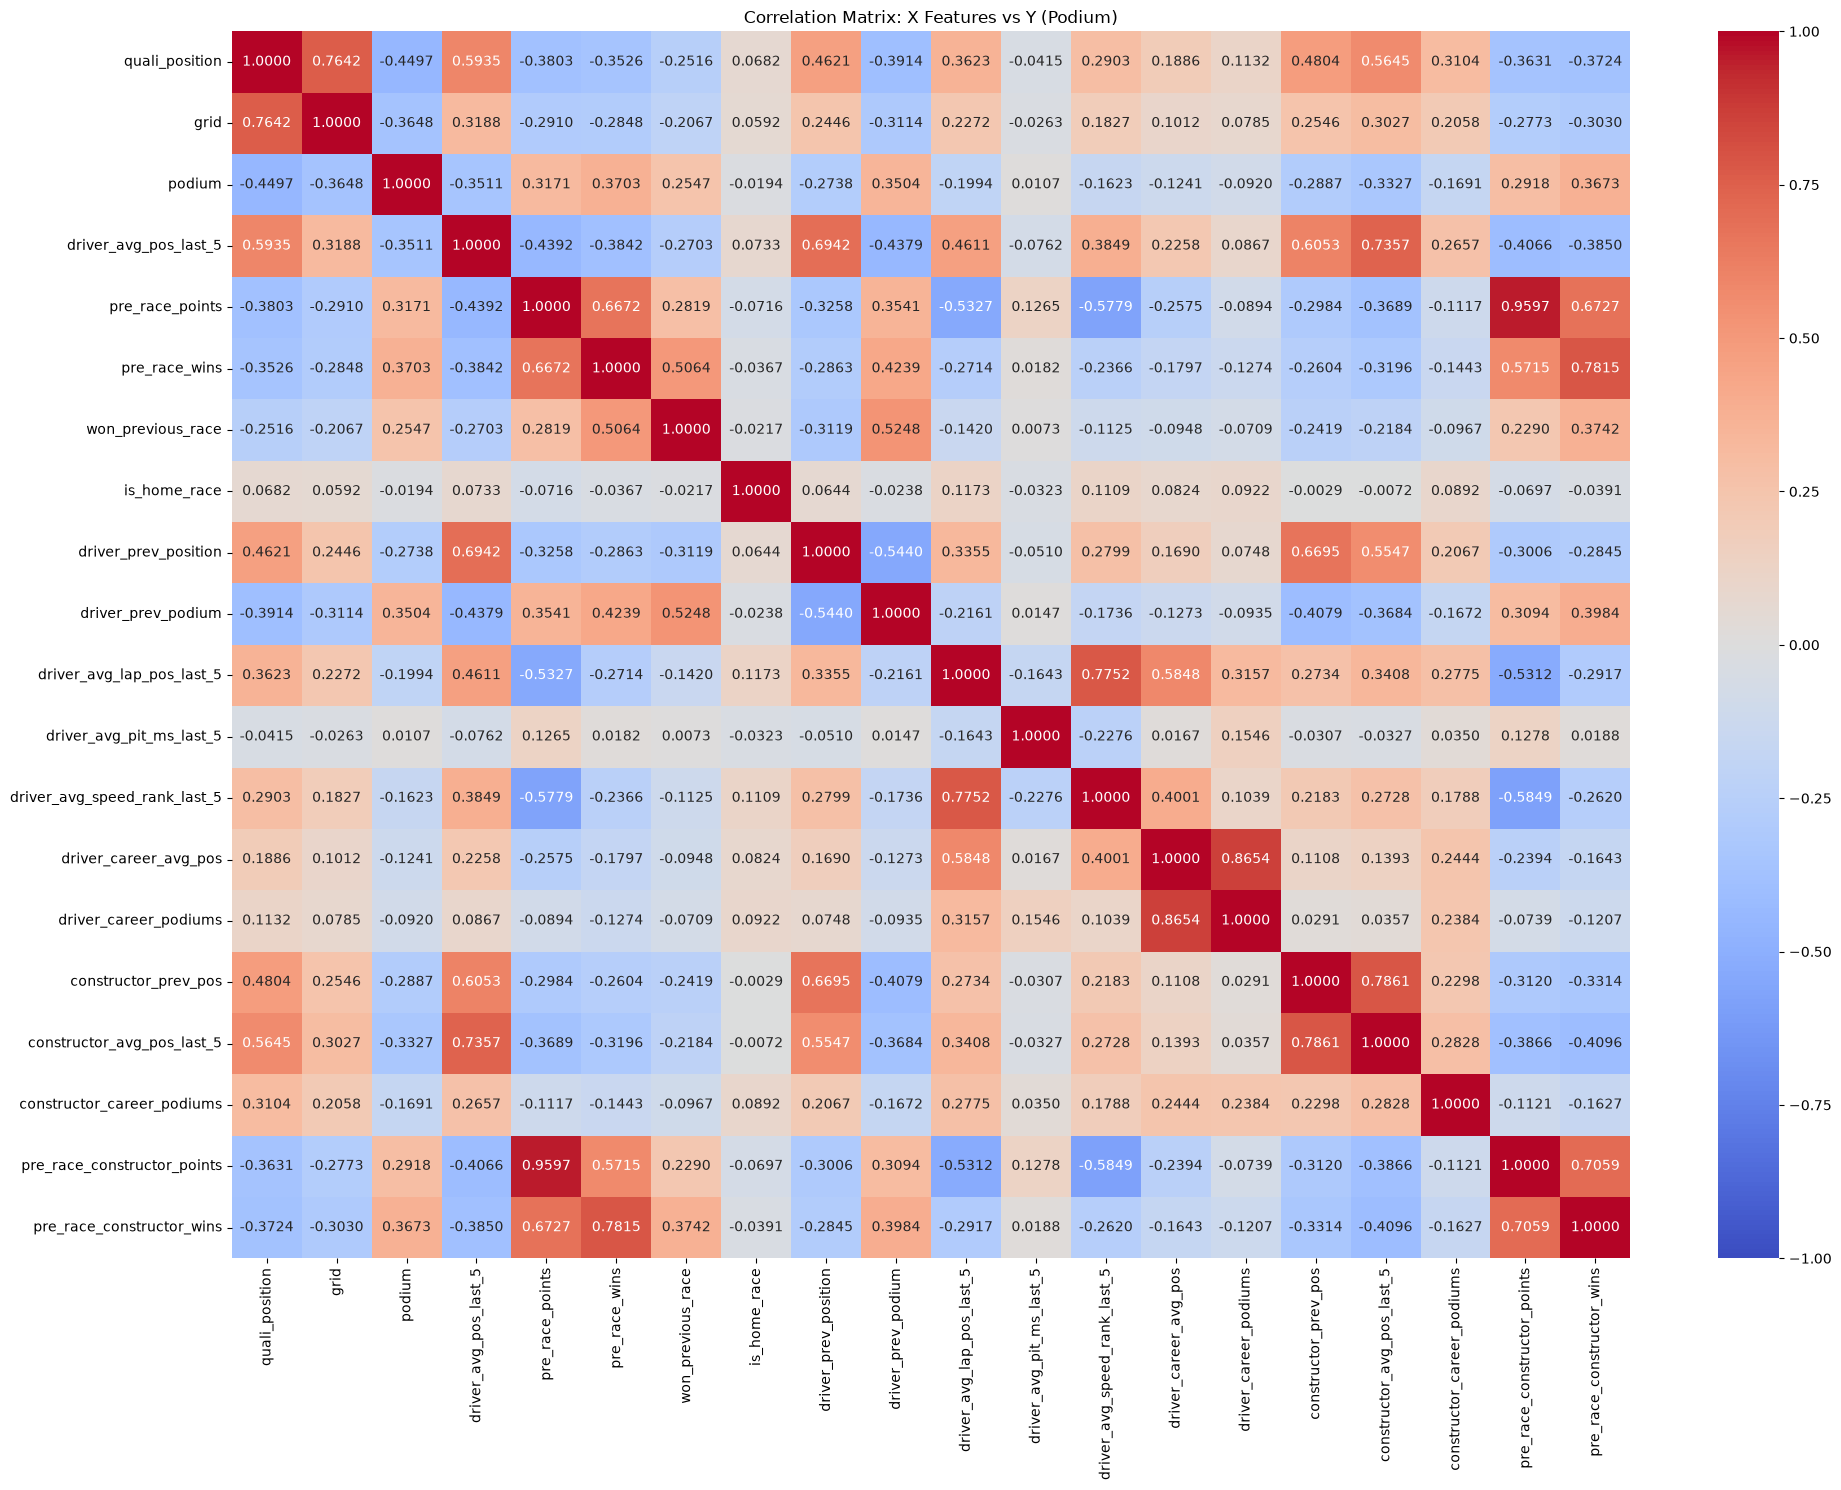

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your two X features and your single Y target variable
selected_columns = ["quali_position", "grid", "podium","driver_avg_pos_last_5","pre_race_points","pre_race_wins","won_previous_race","is_home_race","driver_prev_position","driver_prev_podium","driver_avg_lap_pos_last_5","driver_avg_pit_ms_last_5","driver_avg_speed_rank_last_5","driver_career_avg_pos","driver_career_podiums","constructor_prev_pos","constructor_avg_pos_last_5","constructor_career_podiums","pre_race_constructor_points","pre_race_constructor_wins"]

# 2. Calculate the correlation matrix
matrix = final_df[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
print(matrix)

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(20, 15))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()
